# 01 · Análise Exploratória (EDA)

Objetivo: entender volume, qualidade e distribuição das features e do target.

> As funções de limpeza vêm de `src/churn/data.py`. Ajustes descobertos aqui devem ser levados para lá (não duplicar lógica no notebook).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn.config import CATEGORICAL_FEATURES, NUMERIC_FEATURES, SEED, TARGET
from churn.data import clean, load_raw

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

Matplotlib is building the font cache; this may take a moment.


## 1. Volume e tipos

In [2]:
raw = load_raw()
print(raw.shape)
raw.info()
raw.head()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Qualidade dos dados

- Nulos e brancos (atenção a `TotalCharges`)
- Duplicados
- Cardinalidade das categóricas

In [3]:
print(raw.isna().sum().sum(), 'nulos')
print((raw['TotalCharges'].str.strip() == '').sum(), 'TotalCharges em branco')
print(raw.duplicated(subset='customerID').sum(), 'IDs duplicados')
raw[CATEGORICAL_FEATURES].nunique()

0 nulos
11 TotalCharges em branco
0 IDs duplicados


gender              2
SeniorCitizen       2
Partner             2
Dependents          2
PhoneService        2
MultipleLines       3
InternetService     3
OnlineSecurity      3
OnlineBackup        3
DeviceProtection    3
TechSupport         3
StreamingTV         3
StreamingMovies     3
Contract            3
PaperlessBilling    2
PaymentMethod       4
dtype: int64

In [4]:
df = clean(raw)
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


## 3. Distribuição do target

In [5]:
df[TARGET].value_counts(normalize=True).rename('proporção')

Churn
0    0.73463
1    0.26537
Name: proporção, dtype: float64

### Taxa de churn nos principais fatores de risco

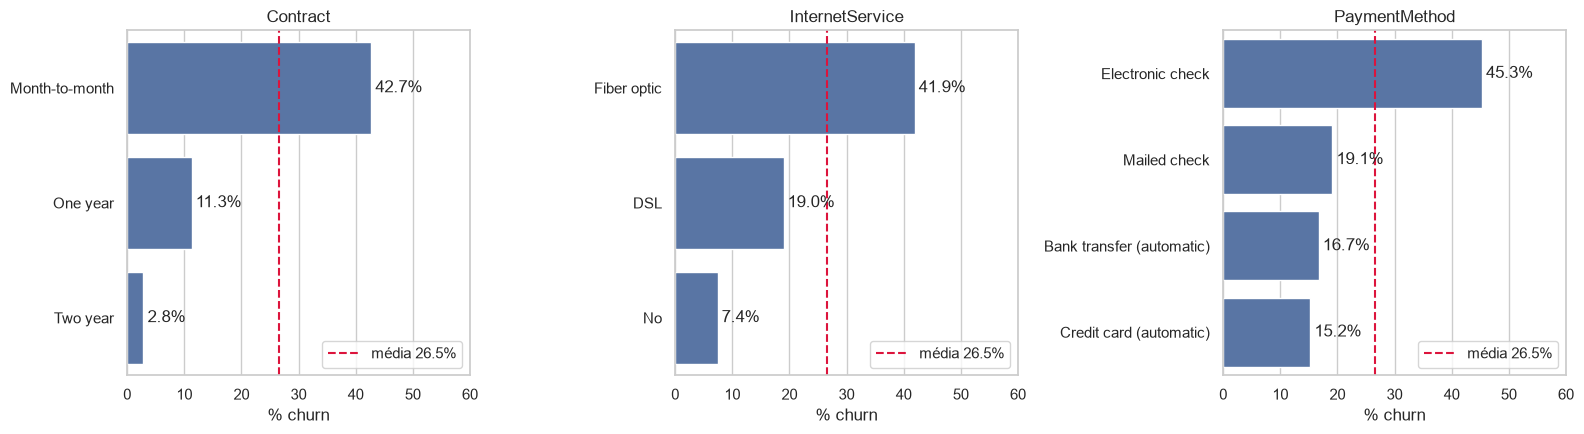

In [6]:
key_factors = ['Contract', 'InternetService', 'PaymentMethod']
overall = df[TARGET].mean()
fig, axes = plt.subplots(1, len(key_factors), figsize=(16, 4.5))
for ax, col in zip(axes, key_factors):
    rate = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color='#4C72B0')
    ax.axvline(overall * 100, color='crimson', linestyle='--', label=f'média {overall:.1%}')
    ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
    ax.set(title=col, xlabel='% churn', ylabel='', xlim=(0, 60))
    ax.legend(loc='lower right')
plt.tight_layout()

## 4. Numéricas vs. churn

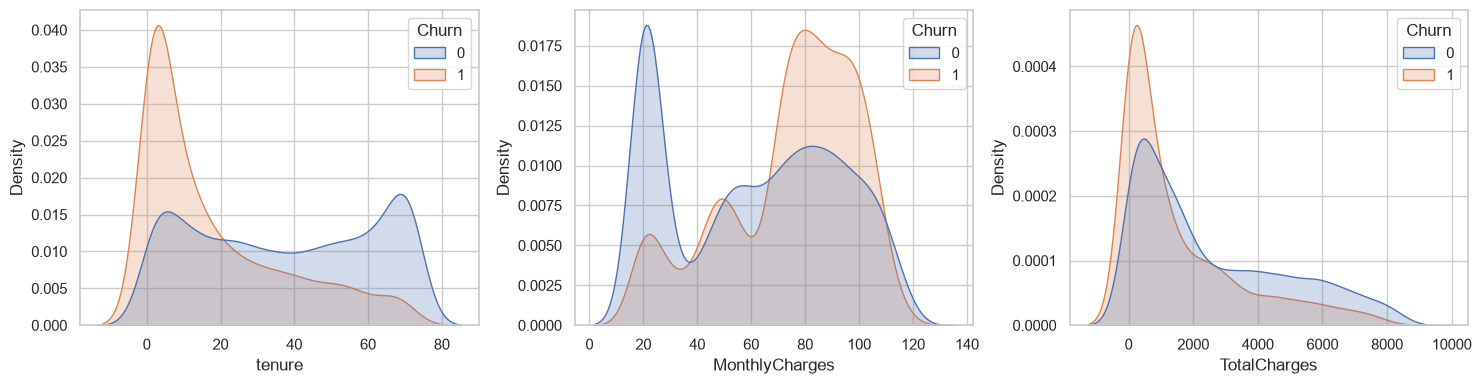

In [7]:
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, fill=True, ax=ax)
plt.tight_layout()

## 5. Categóricas vs. taxa de churn

In [8]:
for col in CATEGORICAL_FEATURES:
    rate = df.groupby(col)[TARGET].agg(['mean', 'size']).rename(columns={'mean': 'churn_rate'})
    display(rate.sort_values('churn_rate', ascending=False))

,churn_rate,size
gender,,
Female,0.269209,3488
Male,0.261603,3555


,churn_rate,size
SeniorCitizen,,
1,0.416813,1142
0,0.236062,5901


,churn_rate,size
Partner,,
No,0.329580,3641
Yes,0.196649,3402


,churn_rate,size
Dependents,,
No,0.312791,4933
Yes,0.154502,2110


,churn_rate,size
PhoneService,,
Yes,0.267096,6361
No,0.249267,682


,churn_rate,size
MultipleLines,,
Yes,0.286099,2971
No,0.250442,3390
No phone service,0.249267,682


... (6 outputs left out)

,churn_rate,size
StreamingMovies,,
No,0.336804,2785
Yes,0.299414,2732
No internet service,0.074050,1526


,churn_rate,size
Contract,,
Month-to-month,0.427097,3875
One year,0.112695,1473
Two year,0.028319,1695


,churn_rate,size
PaperlessBilling,,
Yes,0.335651,4171
No,0.163301,2872


,churn_rate,size
PaymentMethod,,
Electronic check,0.452854,2365
Mailed check,0.191067,1612
Bank transfer (automatic),0.167098,1544
Credit card (automatic),0.152431,1522


## 6. Correlações numéricas

<Axes: >

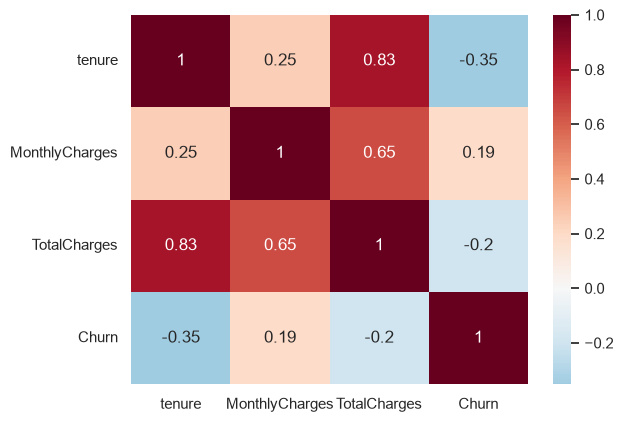

In [9]:
sns.heatmap(df[NUMERIC_FEATURES + [TARGET]].corr(), annot=True, cmap='RdBu_r', center=0)

## 7. Conclusões

- **Volume e qualidade:** 7.043 clientes, 21 colunas, sem IDs duplicados. O único problema é `TotalCharges`,
  que vem como texto com **11 valores em branco**, todos de clientes com `tenure = 0` (ainda não faturados).
  Na limpeza (`churn.data.clean`) esses casos viram 0.
- **Target desbalanceado:** **26,5%** de churn. Por isso:
  - a métrica principal é a **ROC-AUC**, complementada por PR-AUC, F1 e Recall;
  - o split e a validação cruzada são **estratificados**;
  - os modelos usam `class_weight="balanced"` quando suportado.
- **Principais sinais de risco:**
  - **Contrato mensal:** 42,7% de churn, contra 11,3% no anual e 2,8% no de 2 anos.
  - **Internet de fibra:** 41,9%, contra 19,0% com DSL.
  - **Pagamento por electronic check:** 45,3%, contra cerca de 15–19% nos demais meios.
  - **Pouco tempo de casa:** mediana de 10 meses entre quem cancelou, contra 38 entre quem ficou.
  - **Sem suporte técnico ou segurança online:** cerca de 42%, contra cerca de 15% com o serviço.
  - **Idosos (`SeniorCitizen`):** 41,7% de churn, contra 23,6% dos demais.
- **Gênero** praticamente não diferencia o churn (26,9% contra 26,2%).
- **Correlação:** `tenure` e `TotalCharges` são fortemente correlacionadas, como esperado, já que
  TotalCharges ≈ tenure × MonthlyCharges. Isso não atrapalha os modelos de árvore. Na Regressão Logística
  a regularização L2 padrão segura a multicolinearidade.